<a href="https://colab.research.google.com/github/melatisurya/Data_Metopen_Klasifikasi_Penyakit_Daun_Jagung/blob/main/Maize_Leaf_Disease_Colab_Revised_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maize Leaf Disease Classification on Leaf Images Using ResNet50 Transfer Learning and Augmentation
## Revised, leak-free protocol (Google Colab)

This notebook implements the revisions requested after review:

| Review point | Implementation |
|---|---|
| Pixels were divided by 255 although ImageNet ResNet50 expects `preprocess_input` | The architecture's own `preprocess_input` is part of the model |
| Weights were carried over between folds | The model is **rebuilt from ImageNet weights for every fold** |
| Augmentation was created before the fold split (leakage) | **Online augmentation inside the model**, active only on the training portion of each fold; splitting is done on **original images** |
| Backbone fully frozen, training not converged | **Two stages**: (1) frozen backbone, (2) fine-tuning of the last block, both with early stopping |
| 64 test images, no uncertainty | **95% Wilson confidence intervals** for accuracy; mean ± SD over folds; ensemble of fold models |
| Best model picked on test data | Best fold chosen by **validation accuracy**; the test set is used for reporting only |

**Use:** `Runtime → Change runtime type → T4 GPU`, then run all cells from top to bottom (about 15–30 minutes).
Upload the dataset zip (folders `Hawar/`, `Karat/`, `Sehat/`) when asked.

## 0. Get the dataset

In [1]:
import os, zipfile
from google.colab import files, drive

USE_DRIVE = False                                   # True = take the zip from Google Drive
DRIVE_ZIP = '/content/drive/MyDrive/archive.zip'    # change to the zip location in your Drive

if USE_DRIVE:
    drive.mount('/content/drive')
    ZIP_PATH = DRIVE_ZIP
else:
    up = files.upload()                             # choose the dataset zip (310 images)
    ZIP_PATH = list(up.keys())[0]

os.makedirs('/content/data', exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall('/content/data')

DATA_DIR_FOUND = None
for root, dirs, _ in os.walk('/content/data'):
    if {'Hawar', 'Karat', 'Sehat'} <= set(dirs):
        DATA_DIR_FOUND = root
        break
assert DATA_DIR_FOUND, 'Hawar/Karat/Sehat folders not found in the zip'
print('DATA_DIR =', DATA_DIR_FOUND)

Saving archive.zip to archive.zip
DATA_DIR = /content/data/Penyakit Daun Jagung New


## 1. Configuration

In [2]:
import glob, time, random, itertools, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             confusion_matrix, classification_report)
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks

DATA_DIR   = DATA_DIR_FOUND
CLASSES    = ['Hawar', 'Karat', 'Sehat']                # folder names in the dataset
LABELS     = ['Leaf blight', 'Leaf rust', 'Healthy']    # names shown in plots and tables
MODELS     = ['resnet50']
IMG_SIZE   = 224
SEED       = 69
TEST_SIZE  = 0.2
N_FOLDS    = 10
BATCH      = 16
EPOCHS_FE  = 40      # stage 1: frozen backbone (feature extraction)
EPOCHS_FT  = 40      # stage 2: fine-tuning of the last block
LR_FE      = 1e-3
LR_FT      = 1e-5
PATIENCE   = 8
OUT_DIR    = '/content/results'
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(s):
    os.environ['PYTHONHASHSEED'] = str(s)
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)

set_seed(SEED)
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load data and split on the ORIGINAL images
All images are resized once to 224×224 (area interpolation). The 20% test set is separated first and is **never** used for training, augmentation, early stopping, or model selection.

In [3]:
BOX = Image.Resampling.BOX if hasattr(Image, 'Resampling') else Image.BOX   # equivalent to INTER_AREA

def load_resized(path):
    im = Image.open(path)
    im.draft('RGB', (IMG_SIZE * 2, IMG_SIZE * 2))      # speeds up decoding of large JPEGs
    im = im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), BOX)
    return np.asarray(im, dtype=np.uint8)

files_, labels_ = [], []
for ci, cname in enumerate(CLASSES):
    fs = sorted(glob.glob(os.path.join(DATA_DIR, cname, '*')))
    fs = [f for f in fs if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    files_ += fs; labels_ += [ci] * len(fs)
    print(f'{cname}: {len(fs)} images')

y_all = np.array(labels_)
X_all = np.stack([load_resized(f) for f in files_])

idx = np.arange(len(y_all))
tr_idx, te_idx = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
X_tr, y_tr = X_all[tr_idx], y_all[tr_idx]
X_te, y_te = X_all[te_idx], y_all[te_idx]
print('X:', X_all.shape, '| Train:', len(tr_idx), np.bincount(y_tr), '| Test:', len(te_idx), np.bincount(y_te))

Hawar: 107 images
Karat: 102 images
Sehat: 101 images
X: (310, 224, 224, 3) | Train: 248 [85 82 81] | Test: 62 [22 20 20]


## 3. Models
- `preprocess_input` of ResNet50 is **inside** the model (the model takes pixels in 0–255).
- Augmentation (flip, rotation ±18°, zoom ±10%, brightness ±20%, contrast ±20%) is **inside** the model and **only active in training mode**, i.e. only on the training portion of each fold.
- Stage 2 unfreezes the last block; BatchNormalization layers stay frozen.

In [4]:
def get_backbone(name):
    if name == 'resnet50':
        base = tf.keras.applications.ResNet50(include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3))
        prep = tf.keras.applications.resnet50.preprocess_input
        unfreeze_prefix = ('conv5_',)
    else:
        raise ValueError(name)
    return base, prep, unfreeze_prefix


def build_model(name):
    base, prep, unfreeze_prefix = get_backbone(name)
    base.trainable = False
    augment = tf.keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomBrightness(0.2, value_range=(0, 255)),
        layers.RandomContrast(0.2),
    ], name='augment')
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image_0_255')
    x = augment(inputs)                              # active only when training=True
    x = layers.Lambda(prep, name='preprocess')(x)
    x = base(x, training=False)                      # BatchNorm always in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(len(CLASSES), activation='softmax', name='kelas')(x)
    return models.Model(inputs, outputs), base, unfreeze_prefix


def set_finetune(base, unfreeze_prefix):
    base.trainable = True
    n = 0
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization) or not l.name.startswith(unfreeze_prefix):
            l.trainable = False
        else:
            n += 1
    return n


def make_ds(X, y, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((X.astype('float32'), y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)


def compile_model(model, lr):
    model.compile(optimizer=optimizers.Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])


for m in MODELS:
    mm, bb, pp = build_model(m)
    print(m, '| parameters:', mm.count_params(), '| layers unfrozen in stage 2:', set_finetune(bb, pp))
    del mm, bb

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
resnet50 | parameters: 24638339 | layers unfrozen in stage 2: 22


## 4. Evaluation helpers
Accuracy = (number of correct predictions) / n (multiclass). Precision, recall and F1 are weighted averages; AUC is one-vs-rest. The 95% confidence interval of accuracy is the Wilson interval.

In [5]:
def wilson_ci(k, n, z=1.96):
    p = k / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return centre - half, centre + half


def eval_probs(y_true, prob):
    prob = np.asarray(prob, dtype='float64')
    prob = prob / prob.sum(1, keepdims=True)          # make sure probabilities sum to 1 (for AUC)
    pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, average='weighted', zero_division=0)
    f_macro = precision_recall_fscore_support(y_true, pred, average='macro', zero_division=0)[2]
    try:
        auc = roc_auc_score(y_true, prob, multi_class='ovr', average='weighted')
    except ValueError:
        auc = np.nan
    k = int((pred == y_true).sum())
    lo, hi = wilson_ci(k, len(y_true))
    return dict(acc=k / len(y_true), acc_lo=lo, acc_hi=hi, prec_w=p, rec_w=r, f1_w=f, f1_macro=f_macro, auc=auc)


def cm_of(y_true, prob):
    return confusion_matrix(y_true, np.asarray(prob).argmax(1), labels=range(len(CLASSES)))

## 5. Stratified 10-fold cross-validation (model rebuilt in every fold)
For every fold the model is rebuilt from ImageNet weights with a new head. Metrics are recorded after **stage 1** (frozen backbone) and after **stage 2** (fine-tuned), on the validation fold and on the common test set.

In [6]:
def run_cv(name):
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    out = dict(rows=[], hist=[], probs_fe=[], probs_ft=[], val_fe_cm=[], val_ft_cm=[], best=dict(val_acc=-1, weights=None, fold=None))
    t0 = time.time()
    for fold, (a, v) in enumerate(skf.split(X_tr, y_tr), 1):
        tf.keras.backend.clear_session()
        set_seed(SEED + fold)
        model, base, pref = build_model(name)                  # NEW model for every fold
        train_ds, val_ds = make_ds(X_tr[a], y_tr[a], True), make_ds(X_tr[v], y_tr[v], False)
        es = lambda: callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)

        # stage 1: frozen backbone
        compile_model(model, LR_FE)
        h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FE, callbacks=[es()], verbose=0)
        pv1 = model.predict(X_tr[v].astype('float32'), verbose=0)
        pt1 = model.predict(X_te.astype('float32'), verbose=0)

        # stage 2: fine-tune the last block
        set_finetune(base, pref)
        compile_model(model, LR_FT)                             # must recompile after changing trainable
        h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, callbacks=[es()], verbose=0)
        pv2 = model.predict(X_tr[v].astype('float32'), verbose=0)
        pt2 = model.predict(X_te.astype('float32'), verbose=0)

        m = {}
        for tag, pv, pt in (('fe', pv1, pt1), ('ft', pv2, pt2)):
            for k, x in eval_probs(y_tr[v], pv).items():
                m[f'val_{k}_{tag}'] = x
            for k, x in eval_probs(y_te, pt).items():
                m[f'test_{k}_{tag}'] = x
        m['fold'] = fold
        m['epochs_fe'] = len(h1.history['loss']); m['epochs_ft'] = len(h2.history['loss'])
        out['rows'].append(m)
        out['probs_fe'].append(pt1); out['probs_ft'].append(pt2)
        out['hist'].append({k: h1.history[k] + h2.history[k] for k in h1.history} | {'phase_split': len(h1.history['loss'])})
        if m['val_acc_ft'] > out['best']['val_acc']:           # best fold chosen by VALIDATION, not test
            out['best'] = dict(val_acc=m['val_acc_ft'], weights=model.get_weights(), fold=fold)
        print(f"{name} | fold {fold:2d} | val acc fe {m['val_acc_fe']:.3f} -> ft {m['val_acc_ft']:.3f} | "
              f"test acc fe {m['test_acc_fe']:.3f} -> ft {m['test_acc_ft']:.3f} | {time.time()-t0:.0f}s")
    out['df'] = pd.DataFrame(out['rows'])
    return out


RESULTS = {}
for name in MODELS:
    RESULTS[name] = run_cv(name)
    RESULTS[name]['df'].to_csv(f'{OUT_DIR}/results_per_fold_{name}.csv', index=False)

resnet50 | fold  1 | val acc fe 1.000 -> ft 1.000 | test acc fe 0.903 -> ft 0.952 | 127s


resnet50 | fold  2 | val acc fe 0.960 -> ft 0.960 | test acc fe 0.871 -> ft 0.919 | 210s
resnet50 | fold  3 | val acc fe 0.760 -> ft 0.920 | test acc fe 0.919 -> ft 0.952 | 308s
resnet50 | fold  4 | val acc fe 0.920 -> ft 1.000 | test acc fe 0.935 -> ft 0.968 | 398s
resnet50 | fold  5 | val acc fe 0.960 -> ft 0.920 | test acc fe 0.952 -> ft 0.952 | 478s
resnet50 | fold  6 | val acc fe 0.960 -> ft 1.000 | test acc fe 0.887 -> ft 0.952 | 596s
resnet50 | fold  7 | val acc fe 0.960 -> ft 1.000 | test acc fe 0.903 -> ft 0.968 | 698s
resnet50 | fold  8 | val acc fe 1.000 -> ft 1.000 | test acc fe 0.887 -> ft 0.935 | 802s
resnet50 | fold  9 | val acc fe 1.000 -> ft 1.000 | test acc fe 0.952 -> ft 0.952 | 919s
resnet50 | fold 10 | val acc fe 0.917 -> ft 1.000 | test acc fe 0.919 -> ft 0.952 | 1046s


## 6. Summary tables (for the Results section)

In [7]:
def mean_sd(df, col):
    return f"{df[col].mean():.3f} ± {df[col].std(ddof=1):.3f}"

# 6a. Cross-validation (validation folds): mean ± SD over folds
cv_rows = []
for name, R in RESULTS.items():
    df = R['df']
    for tag, nm in (('fe', 'frozen backbone'), ('ft', 'fine-tuned')):
        cv_rows.append({'model': name, 'stage': nm, 'val_acc': mean_sd(df, f'val_acc_{tag}'),
                        'val_f1_w': mean_sd(df, f'val_f1_w_{tag}'), 'val_auc': mean_sd(df, f'val_auc_{tag}')})
cv_table = pd.DataFrame(cv_rows); cv_table.to_csv(f'{OUT_DIR}/table_crossval.csv', index=False)
print(cv_table.to_string(index=False))

# 6b. Test set (64-ish images): mean ± SD of fold models, and the ensemble with 95% Wilson CI
test_rows = []
for name, R in RESULTS.items():
    df = R['df']
    for tag, nm, key in (('fe', 'frozen backbone', 'probs_fe'), ('ft', 'fine-tuned', 'probs_ft')):
        ens = eval_probs(y_te, np.mean(R[key], axis=0))
        test_rows.append({'model': name, 'stage': nm,
                          'fold-model acc (mean ± SD)': mean_sd(df, f'test_acc_{tag}'),
                          'weighted precision': mean_sd(df, f'test_prec_w_{tag}'),
                          'weighted F1': mean_sd(df, f'test_f1_w_{tag}'),
                          'AUC': mean_sd(df, f'test_auc_{tag}'),
                          'ensemble acc [95% CI]': f"{ens['acc']:.3f} [{ens['acc_lo']:.3f}, {ens['acc_hi']:.3f}]",
                          'ensemble F1': f"{ens['f1_w']:.3f}", 'ensemble AUC': f"{ens['auc']:.3f}"})
test_table = pd.DataFrame(test_rows); test_table.to_csv(f'{OUT_DIR}/table_test.csv', index=False)
print(); print(test_table.to_string(index=False))

# 6c. Best fold by VALIDATION accuracy: its test result with 95% CI
best_rows = []
for name, R in RESULTS.items():
    f = R['best']['fold']
    r = R['df'].loc[f - 1]
    lo, hi = r['test_acc_lo_ft'], r['test_acc_hi_ft']
    best_rows.append({'model': name, 'best fold (by val acc)': f, 'val acc': round(r['val_acc_ft'], 3),
                      'test acc [95% CI]': f"{r['test_acc_ft']:.3f} [{lo:.3f}, {hi:.3f}]",
                      'test F1 (w)': round(r['test_f1_w_ft'], 3), 'test AUC': round(r['test_auc_ft'], 3)})
best_table = pd.DataFrame(best_rows); best_table.to_csv(f'{OUT_DIR}/table_best_fold.csv', index=False)
print(); print(best_table.to_string(index=False))

   model           stage       val_acc      val_f1_w       val_auc
resnet50 frozen backbone 0.944 ± 0.071 0.943 ± 0.073 0.988 ± 0.023
resnet50      fine-tuned 0.980 ± 0.034 0.980 ± 0.034 0.995 ± 0.010

   model           stage fold-model acc (mean ± SD) weighted precision   weighted F1           AUC ensemble acc [95% CI] ensemble F1 ensemble AUC
resnet50 frozen backbone              0.913 ± 0.028      0.919 ± 0.024 0.913 ± 0.028 0.982 ± 0.007  0.952 [0.867, 0.983]       0.952        0.985
resnet50      fine-tuned              0.950 ± 0.014      0.951 ± 0.014 0.950 ± 0.014 0.994 ± 0.003  0.952 [0.867, 0.983]       0.952        0.996

   model  best fold (by val acc)  val acc    test acc [95% CI]  test F1 (w)  test AUC
resnet50                       1      1.0 0.952 [0.867, 0.983]        0.952     0.993


## 7. Figures and error analysis

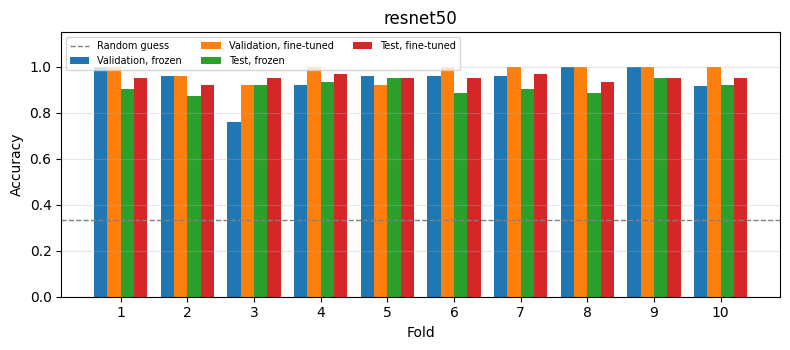

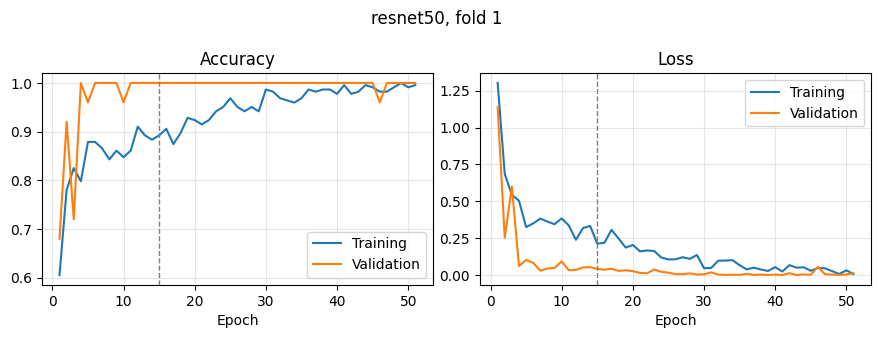

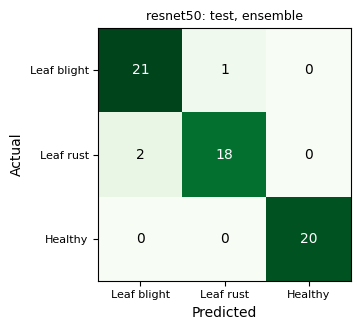

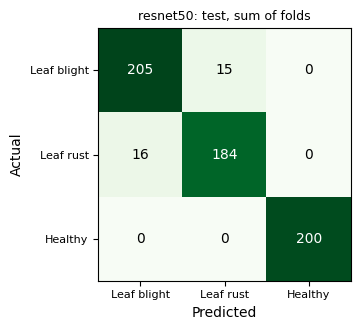

--- resnet50: per-class report of the ensemble on the test set ---
              precision    recall  f1-score   support

 Leaf blight      0.913     0.955     0.933        22
   Leaf rust      0.947     0.900     0.923        20
     Healthy      1.000     1.000     1.000        20

    accuracy                          0.952        62
   macro avg      0.953     0.952     0.952        62
weighted avg      0.952     0.952     0.952        62



In [8]:
def plot_cm(cm, title, path):
    fig, ax = plt.subplots(figsize=(3.8, 3.4))
    ax.imshow(cm, cmap='Greens')
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        ax.text(j, i, int(cm[i, j]), ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
    ax.set_xticklabels(LABELS, fontsize=8); ax.set_yticklabels(LABELS, fontsize=8)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(title, fontsize=9)
    plt.tight_layout(); plt.savefig(path, dpi=200); plt.show()


for name, R in RESULTS.items():
    # accuracy per fold: validation vs test, stage 1 vs stage 2
    fig, ax = plt.subplots(figsize=(8, 3.6)); x = np.arange(1, N_FOLDS + 1); df = R['df']
    ax.bar(x - 0.3, df['val_acc_fe'], 0.2, label='Validation, frozen')
    ax.bar(x - 0.1, df['val_acc_ft'], 0.2, label='Validation, fine-tuned')
    ax.bar(x + 0.1, df['test_acc_fe'], 0.2, label='Test, frozen')
    ax.bar(x + 0.3, df['test_acc_ft'], 0.2, label='Test, fine-tuned')
    ax.axhline(1 / len(CLASSES), color='gray', ls='--', lw=1, label='Random guess')
    ax.set_xticks(x); ax.set_xlabel('Fold'); ax.set_ylabel('Accuracy'); ax.set_ylim(0, 1.15)
    ax.legend(fontsize=7, ncol=3, loc='upper left'); ax.grid(axis='y', alpha=.3); ax.set_title(name)
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/accuracy_per_fold_{name}.png', dpi=200); plt.show()

    # learning curves of the best fold (dashed line = start of fine-tuning)
    h = R['hist'][R['best']['fold'] - 1]; ep = np.arange(1, len(h['loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
    ax[0].plot(ep, h['accuracy'], label='Training'); ax[0].plot(ep, h['val_accuracy'], label='Validation'); ax[0].set_title('Accuracy')
    ax[1].plot(ep, h['loss'], label='Training'); ax[1].plot(ep, h['val_loss'], label='Validation'); ax[1].set_title('Loss')
    for a_ in ax:
        a_.axvline(h['phase_split'], color='gray', ls='--', lw=1); a_.set_xlabel('Epoch'); a_.legend(); a_.grid(alpha=.3)
    plt.suptitle(f"{name}, fold {R['best']['fold']}"); plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/training_curves_{name}.png', dpi=200); plt.show()

    # confusion matrices on the test set (fine-tuned): ensemble and sum of fold models
    ens = np.mean(R['probs_ft'], axis=0)
    plot_cm(cm_of(y_te, ens), f'{name}: test, ensemble', f'{OUT_DIR}/cm_test_ensemble_{name}.png')
    plot_cm(np.sum([cm_of(y_te, p) for p in R['probs_ft']], axis=0), f'{name}: test, sum of folds', f'{OUT_DIR}/cm_test_sum_{name}.png')
    print(f'--- {name}: per-class report of the ensemble on the test set ---')
    print(classification_report(y_te, ens.argmax(1), target_names=LABELS, digits=3, zero_division=0))

## 8. Download the results

In [9]:
shutil.make_archive('/content/experiment_results', 'zip', OUT_DIR)
files.download('/content/experiment_results.zip')     # CSV tables and figures

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes for the article
- Send `table_crossval.csv`, `table_test.csv`, `table_best_fold.csv`, `results_per_fold_*.csv` and the printed per-class reports to Claude to fill the Results and Discussion.
- Report the numbers as they are, including when fine-tuning does not help.
- Early stopping uses the validation fold, so validation accuracy is slightly optimistic; the test set is the unbiased estimate.
- The test set is small (about 62 images): always quote the 95% confidence interval.